# The ankle paper's gait-phase ensemble as the baseline: anomaly detection is not regime selection

Tourk et al. ([arXiv:2508.21221](https://arxiv.org/abs/2508.21221)) found an ensemble of seven gait-phase TCNs the best of
their four uncertainty estimators (Table I: F1 90.3 against 55.7 for the autoencoder's latent LOF). Its score is the
members' disagreement, $\Psi = (\mathrm{Var}(l_1..l_7) + \mathrm{Var}(r_1..r_7)) / 2$, thresholded at the 99.5th percentile
of training $\Psi$: a window is in distribution (actuate) or out of it (do not actuate). This notebook trains that
estimator on the Nature data (`ml/nature/awareness/train_ensemble.py`, targets from the insoles via `ensemble_data.py`)
and asks two questions:

1. On the paper's own task, unfamiliar against familiar movement, how does $\Psi$ compare with the autoencoders and VAEs
   of notebook 05?
2. On this project's task, choosing between **three** controllers (ID-safe: spline; OOD-safe: joint-moment estimator;
   OOD-dangerous: exo off), does $\Psi$ separate OOD-safe from OOD-dangerous the way notebook 09's aggregated
   uncertainty $u$ does?

| | |
|---|---|
| model | `ml/common/models/ensemble.py`: 7 TCNs, 3 causal layers x 30 filters, kernel 20, dilations (1, 2, 8); two tanh heads, sin(2π phase) per leg at the window's last sample |
| inputs | the 1 s raw windows (16 channels x 200 samples) of `ae_data.py`, the paper's window |
| targets | gait phase from heel strikes read off the insole vertical force (`ensemble_data.py`); a window trains the heads whose leg has a phase |
| training | ID-safe windows of the training participants; Adam 1e-3, batch 1,024; `val`: early stopping on the validation participants (patience 10, the project's convention); `loso`: the paper's two-stage protocol |
| scoring | $\Psi$ after the 0.5 s causal median by recording (notebooks 05, 09); the paper's threshold, the 1% false-alarm operating point on the validation participants, and two regime cutoffs chosen on the validation participants; test participants scored once; seeds 0-2 |

Results go to `results/10_*.csv`, figures to `figures/10_*.png`. Runs: `submit.sh --ensemble`, then `pull.sh`.

## Findings at a glance

Six runs (seeds 0-2 under each protocol; the paper's LOSO chose 7-8 epochs, validation early stopping 6-9) agree to the
second decimal, so the numbers below are the `val` protocol's mean over seeds; `results/10_ensemble_scores.csv` has both.

- **On its own task, $\Psi$ is a fair unfamiliar-movement detector and a very good dangerous-movement one.** Test AUROC
  0.88 for unfamiliar against familiar (LSTM-VAE 0.963, plain AE 0.950, notebook 05), 0.992 for OOD-dangerous against
  familiar (equal to the best latent models). At the paper's threshold it flags 62% of unfamiliar and 93% of dangerous
  windows at 0.5% false alarms; at the project's 1% operating point (1.9% on the test participants, the same wearer drift
  as notebook 05) 71% and 96%. The ensemble does estimate phase on the cyclic tasks (RMSE of sin phase 0.15-0.18 on
  walking, 0.20 on stairs, section 1).
- **It does not make the three-way choice.** ID-safe against OOD-safe AUROC 0.86 ($u$: 0.98); OOD-safe against
  OOD-dangerous 0.78 ($u$: 0.965). With the two cutoffs chosen on validation, macro F1 0.60 against 0.868: 14% of safe
  windows switched off ($u$: 2%), 54% of dangerous windows recognised, and 0.5% of dangerous windows still sent to the
  spline ($u$: none). The histogram (section 3) shows why: ID-safe and OOD-safe overlap over two decades of $\Psi$, and
  OOD-safe and OOD-dangerous overlap over the top decade.
- **Per task, $\Psi$ orders by distance from the gait cycle, not by danger.** Ball toss, sit-to-stand and tug of war sit at
  the top, but interleaved with squats, lift weight, jump and lunges (all OOD-safe), and step-ups sit mid-range below side
  shuffle and lunges. Median $\Psi$ against the share of a task's windows with a detectable stride: Spearman −0.80
  (section 4). The paper states the limit itself (gait phase is undefined off the cycle); the score has no second axis to
  tell "unfamiliar, and the estimator copes" from "unfamiliar, and the estimator fails".
- $\Psi$ and $u$ rank the tasks alike (Spearman 0.84 of the task medians): both agree on *what is unusual*. What $u$ adds
  is the regime axis (the estimator band at 0.5 that nearly every OOD-safe task lands in); on $\Psi$ that band has to be cut
  out of one continuous novelty scale, and the overlap above decides the error rates.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ml' / 'nature' / 'nature_data.py').exists())
for folder in ('ml/common', 'ml/nature', 'notebooks/nature/model_exploration/onboard'):
    if str(REPO / folder) not in sys.path:
        sys.path.insert(0, str(REPO / folder))
import _novelty_scores as ns
import _regime_classifier as rc
import _ensemble_baseline as eb

ROOT = REPO / 'notebooks' / 'nature' / 'model_exploration'
DATA = REPO / 'data' / 'processed_nature' / 'ae'
RUNS = ROOT / 'runs' / 'ensemble'
RESULTS, FIG_DIR = Path.cwd() / 'results', Path.cwd() / 'figures'
pd.set_option('display.width', 220)

meta = json.loads((DATA / 'meta.json').read_text())
windows = pd.read_parquet(DATA / meta['inputs']['raw_1s']['table'])
FAMILIAR = tuple(meta['id_tasks'])
coverage = pd.DataFrame(json.loads((DATA / 'gait_phase.json').read_text())['per_task']).set_index('task')
runs = eb.discover_runs(RUNS)
if runs.empty:
    raise FileNotFoundError(f'no finished runs under {RUNS}: submit.sh --ensemble on the cluster, then pull.sh')
PROTOCOL = 'val' if 'val' in set(runs['protocol']) else runs['protocol'].iloc[0]      # the protocol the figures pool over
runs['name'] = runs['run'].map(lambda p: p.name)
display(runs.drop(columns = 'run'))
exports = {r.name: {'val': eb.load_scores(r.run, windows, 'scores_val.npz'), 'test': eb.get_test_part(eb.load_scores(r.run, windows))}
           for r in runs.itertuples()}
first = next(iter(exports.values()))
print(f"{len(first['val']['psi']):,} validation and {len(first['test']['psi']):,} test windows per run; {len(runs)} runs; figures pool the {PROTOCOL!r} protocol")

,protocol,seed,threshold,val_mse,epochs_run,best_epoch,name
0,loso,0,0.018343,0.065976,8,7,ensemble_loso_s0
1,loso,1,0.015282,0.065474,7,6,ensemble_loso_s1
2,loso,2,0.015060,0.065621,7,6,ensemble_loso_s2
3,val,0,0.021819,0.065573,20,9,ensemble_s0
4,val,1,0.017419,0.065288,18,7,ensemble_s1
5,val,2,0.015060,0.065621,17,6,ensemble_s2


177,582 validation and 140,954 test windows per run; 6 runs; figures pool the 'val' protocol


## 1. The ensemble does estimate gait phase on the cyclic tasks

A sanity check before $\Psi$ means anything: the RMSE of the ensemble mean against sin(2π phase) on the test participants'
labelled legs, per task (tasks whose insoles show no stride have no label and are absent). The validation MSE at the
chosen epoch is in `summary.json`.

In [2]:
rmse = pd.concat({name: eb.get_phase_rmse_per_task(ex['test']) for name, ex in exports.items()}, axis = 1)
rmse['mean'], rmse['sd'] = rmse.mean(axis = 1), rmse.std(axis = 1)
rmse['regime'] = [coverage.loc[t, 'controller_class'] for t in rmse.index]
rmse['phase coverage'] = coverage.loc[rmse.index, 'coverage'].to_numpy()
display(rmse.sort_values('mean').round(3))

,ensemble_loso_s0,ensemble_loso_s1,ensemble_loso_s2,ensemble_s0,ensemble_s1,ensemble_s2,mean,sd,regime,phase coverage
weighted_walk,0.152,0.157,0.151,0.154,0.151,0.151,0.153,0.003,ID-safe,0.978
curb_up,0.173,0.151,0.169,0.168,0.164,0.169,0.166,0.008,OOD-safe,0.941
normal_walk,0.172,0.175,0.172,0.180,0.173,0.172,0.174,0.003,ID-safe,0.956
incline_walk,0.172,0.186,0.174,0.175,0.173,0.174,0.176,0.005,ID-safe,0.969
stairs,0.204,0.208,0.202,0.201,0.203,0.202,0.203,0.003,ID-safe,0.813
obstacle_walk,0.211,0.226,0.219,0.218,0.214,0.219,0.218,0.005,OOD-safe,0.978
curb_down,0.286,0.277,0.284,0.285,0.288,0.284,0.284,0.004,OOD-safe,0.928
meander,0.339,0.336,0.346,0.347,0.351,0.346,0.344,0.006,OOD-safe,0.350
step_ups,0.359,0.330,0.369,0.352,0.320,0.369,0.350,0.021,OOD-dangerous,0.163
dynamic_walk,0.351,0.348,0.351,0.366,0.357,0.351,0.354,0.007,OOD-safe,0.959


## 2. The paper's task: unfamiliar against familiar

Every number on the test participants, per run and as mean ± SD over seeds. The paper's rule: filtered $\Psi$ above the
99.5th percentile of the training windows' $\Psi$. The project's operating point: the threshold that flags 1% of the
validation participants' familiar windows (notebook 05, section 6). The reference rows are notebook 05's native scores,
each model type's best (model, score) by validation AUROC.

In [3]:
rows = []
for r in runs.itertuples():
    ex = exports[r.name]
    rows.append({'run': r.name, 'protocol': r.protocol, 'seed': r.seed, **eb.evaluate_run(ex['val'], ex['test'], r.threshold, FAMILIAR)})
scores = pd.DataFrame(rows)
scores.to_csv(RESULTS / '10_ensemble_scores.csv', index = False)
agg = scores.drop(columns = ['run', 'seed']).groupby('protocol').agg(['mean', 'std'])
anomaly = [c for c in scores.columns if c.startswith('paper rule') or c.startswith('1% FA rule')]
display(agg[anomaly].T.round(3))
print('reference: notebook 05 (ID-trained autoencoders and VAEs), test AUROC mean ± sd over seeds')
display(eb.get_reference_detectors(RESULTS / '05_native_scores.csv').round(3))

protocol                                             loso     val
paper rule: AUROC, unfamiliar vs familiar    mean   0.880   0.882
                                             std    0.001   0.002
paper rule: AUROC, OOD-safe vs familiar      mean   0.860   0.863
                                             std    0.002   0.003
paper rule: AUROC, OOD-dangerous vs familiar mean   0.992   0.992
                                             std    0.001   0.001
paper rule: flagged, unfamiliar (%)          mean  62.215  62.118
                                             std    2.627   2.754
paper rule: flagged, OOD-dangerous (%)       mean  93.471  92.747
                                             std    1.233   1.988
paper rule: false alarms, familiar (%)       mean   0.630   0.542
                                             std    0.145   0.205
1% FA rule: flagged, unfamiliar (%)          mean  71.015  71.125
                                             std    1.301   0.867
1% FA rule: flagged, OOD-dangerous (%)       mean  96.587  96.468
                                             std    0.552   0.499
1% FA rule: false alarms, familiar (%)       mean   1.915   1.909
                                             std    0.085   0.131

reference: notebook 05 (ID-trained autoencoders and VAEs), test AUROC mean ± sd over seeds


,type,model,score,"test AUROC, unfamiliar vs familiar","test AUROC, OOD-dangerous vs familiar","test AUROC, unfamiliar vs familiar sd","test AUROC, OOD-dangerous vs familiar sd"
1,LSTM-VAE,LSTM-VAE · β 1 · fixed variance · 3 s raw,"LOF, raw latent",0.963,0.993,0.004,0.003
5,plain AE,vanilla · 3 s raw,"LOF, raw latent",0.950,0.987,0.006,0.012
2,TCN-VAE,TCN-VAE · β 1 · fixed variance · 3 s raw,"LOF, raw latent",0.950,0.995,0.007,0.003
3,Transformer VAE,Transformer VAE · β 1 · fixed variance · 3 s raw,"LOF, active dimensions",0.949,0.985,0.003,0.005
0,Gaussian-NLL AE,gaussian · 3 s raw,"LOF, raw latent",0.943,0.987,0.008,0.007
4,conv VAE,VAE · β 1 · fixed variance · 3 s raw,"LOF, raw latent",0.939,0.988,0.013,0.009
6,sparse AE,sparse · 3 s raw · λ 0.3,"LOF, raw latent",0.907,0.937,0.016,0.040


## 3. This project's task: three regimes

The AUROCs that matter for controller selection, ID-safe against OOD-safe and OOD-safe against OOD-dangerous, and the two
cutoffs that split $\Psi$ into spline / estimator / exo off (chosen on the validation participants by macro F1, as
notebook 09 chose them for $u$). The reference row is notebook 09's $u$ from the regime classifier alone.

In [4]:
three_way = ['AUROC, ID-safe vs OOD-safe', 'AUROC, OOD-safe vs dangerous', 'macro F1', 'recall, ID-safe', 'recall, OOD-safe',
             'recall, OOD-dangerous', 'dangerous sent to the spline (%)', 'safe switched off (%)']
display(agg[three_way].T.round(3))
ref09 = pd.read_csv(RESULTS / '09_uncertainty_scores.csv')
ref09 = ref09[ref09['configuration'] == 'regime classifier alone']
CUTOFFS_09 = (float(ref09['cutoff, spline | estimator'].iloc[0]), float(ref09['cutoff, estimator | off'].iloc[0]))
print('reference: notebook 09, u from the regime classifier alone (mean ± sd over seeds)')
display(ref09[['AUROC, ID-safe vs OOD-safe', 'AUROC, OOD-safe vs dangerous', 'test macro F1 (cutoffs)', 'dangerous sent to the spline (%)',
               'safe switched off (%)']].agg(['mean', 'std']).round(3))

protocol                                 loso     val
AUROC, ID-safe vs OOD-safe       mean   0.860   0.863
                                 std    0.002   0.003
AUROC, OOD-safe vs dangerous     mean   0.779   0.775
                                 std    0.017   0.017
macro F1                         mean   0.605   0.602
                                 std    0.018   0.021
recall, ID-safe                  mean   0.857   0.863
                                 std    0.014   0.021
recall, OOD-safe                 mean   0.623   0.622
                                 std    0.031   0.035
recall, OOD-dangerous            mean   0.561   0.541
                                 std    0.005   0.021
dangerous sent to the spline (%) mean   0.494   0.526
                                 std    0.126   0.114
safe switched off (%)            mean  13.693  13.949
                                 std    2.865   3.130

reference: notebook 09, u from the regime classifier alone (mean ± sd over seeds)


,"AUROC, ID-safe vs OOD-safe","AUROC, OOD-safe vs dangerous",test macro F1 (cutoffs),dangerous sent to the spline (%),safe switched off (%)
mean,0.981,0.965,0.868,0.0,2.067
std,0.003,0.000,0.005,0.0,0.134


Where each regime's windows sit on filtered $\Psi$ (test participants, the pooled seeds of one protocol), with the bands
the validation cutoffs give. The quantile cutoffs are mapped back to $\Psi$ through the pooled validation scores.

pooled cutoffs on Psi: 0.003468 (spline | estimator), 0.05679 (estimator | off); test macro F1 0.601, dangerous sent to the spline 0.5%, safe switched off 13.1%


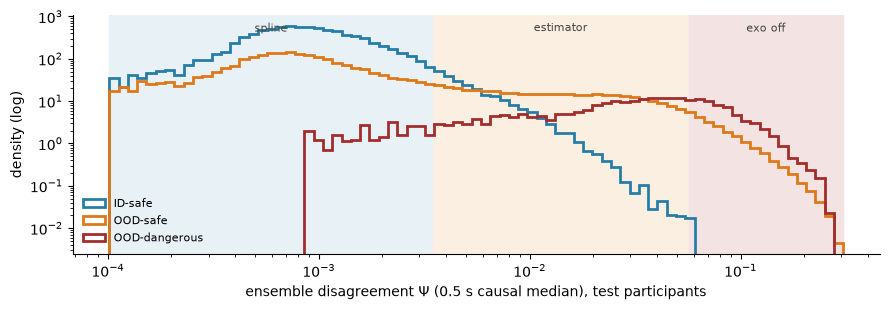

In [5]:
pooled = [n for n in exports if runs.set_index('name').loc[n, 'protocol'] == PROTOCOL]
f_val = np.concatenate([ns.get_filtered(exports[n]['val']['psi'], exports[n]['val']['labels']) for n in pooled])
f_test = np.concatenate([ns.get_filtered(exports[n]['test']['psi'], exports[n]['test']['labels']) for n in pooled])
y_val = np.concatenate([exports[n]['val']['labels']['controller_class'].astype(str).to_numpy() for n in pooled])
y_test = np.concatenate([exports[n]['test']['labels']['controller_class'].astype(str).to_numpy() for n in pooled])
tasks_test = np.concatenate([exports[n]['test']['labels']['task'].astype(str).to_numpy() for n in pooled])
to_q = eb.get_quantile_map(f_val)
cutoffs_q = rc.get_cutoffs(to_q(f_val), y_val)
cutoffs_psi = tuple(float(np.quantile(f_val, c)) for c in cutoffs_q)
pooled_metrics = rc.get_regime_metrics(y_test, rc.get_banded(to_q(f_test), cutoffs_q))
print(f'pooled cutoffs on Psi: {cutoffs_psi[0]:.4g} (spline | estimator), {cutoffs_psi[1]:.4g} (estimator | off); '
      f"test macro F1 {pooled_metrics['macro F1']:.3f}, dangerous sent to the spline {pooled_metrics['dangerous sent to the spline (%)']:.1f}%, "
      f"safe switched off {pooled_metrics['safe switched off (%)']:.1f}%")
BAND = [('spline', '#e8f1f6'), ('estimator', '#fbefe2'), ('exo off', '#f4e3e3')]
lo, hi = np.quantile(f_test[f_test > 0], 0.001), f_test.max()
bins = np.logspace(np.log10(lo), np.log10(hi), 80)
fig, ax = plt.subplots(figsize = (9, 3.2))
edges = [lo, *cutoffs_psi, hi]
for k, (band, colour) in enumerate(BAND):
    ax.axvspan(edges[k], edges[k + 1], color = colour, zorder = 0)
    ax.text(np.sqrt(edges[k] * edges[k + 1]), .97, band, transform = ax.get_xaxis_transform(), ha = 'center', va = 'top', fontsize = 8, color = '#444')
for r in rc.REGIMES:
    ax.hist(np.clip(f_test[y_test == r], lo, hi), bins = bins, density = True, histtype = 'step', linewidth = 2, color = eb.REGIME_C[r], label = r)
ax.set(xscale = 'log', yscale = 'log', xlabel = r'ensemble disagreement $\Psi$ (0.5 s causal median), test participants', ylabel = 'density (log)')
ax.legend(frameon = False, fontsize = 8, loc = 'lower left')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / '10_psi_by_regime.png', dpi = 160, bbox_inches = 'tight')
plt.show()

Per task, side by side: the ensemble's $\Psi$ (left) and notebook 09's $u$ (right, from `results/09_uncertainty_per_task.csv`),
each the median and interquartile range over the test participants' windows, tasks sorted by median, coloured by regime,
dashed lines at the cutoffs chosen on validation. The question is whether the red tasks sit to the right of the orange ones.

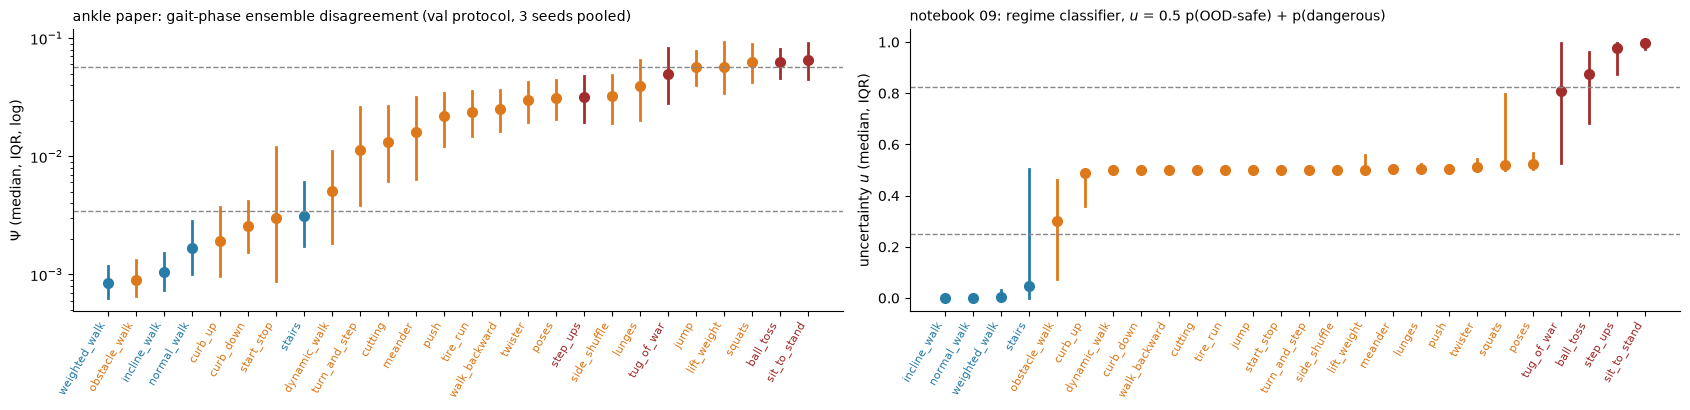

rank correlation of task medians between Psi and u: 0.837


In [6]:
per_psi = eb.get_per_task(f_test, pd.DataFrame({'task': tasks_test, 'controller_class': y_test}))
per_psi.to_csv(RESULTS / '10_ensemble_per_task.csv', index = False)
per_u = pd.read_csv(RESULTS / '09_uncertainty_per_task.csv')
fig, axes = plt.subplots(1, 2, figsize = (17, 4.2), gridspec_kw = {'width_ratios': [1, 1]})
eb.plot_per_task(axes[0], per_psi, cutoffs_psi, r'$\Psi$ (median, IQR, log)', log = True,
                 title = f'ankle paper: gait-phase ensemble disagreement ({PROTOCOL} protocol, {len(pooled)} seeds pooled)')
eb.plot_per_task(axes[1], per_u, CUTOFFS_09, 'uncertainty $u$ (median, IQR)', title = 'notebook 09: regime classifier, $u$ = 0.5 p(OOD-safe) + p(dangerous)')
fig.tight_layout()
fig.savefig(FIG_DIR / '10_per_task_vs_09.png', dpi = 160, bbox_inches = 'tight')
plt.show()
print('rank correlation of task medians between Psi and u:', round(per_psi.set_index('task')['50%'].corr(per_u.set_index('task')['50%'], method = 'spearman'), 3))

The same per-task panel on a linear axis, for comparison. Ψ spans about two orders of magnitude, so most tasks
collapse towards zero; the log panel above is the one to read for task order, this one for how far apart the scores really are.

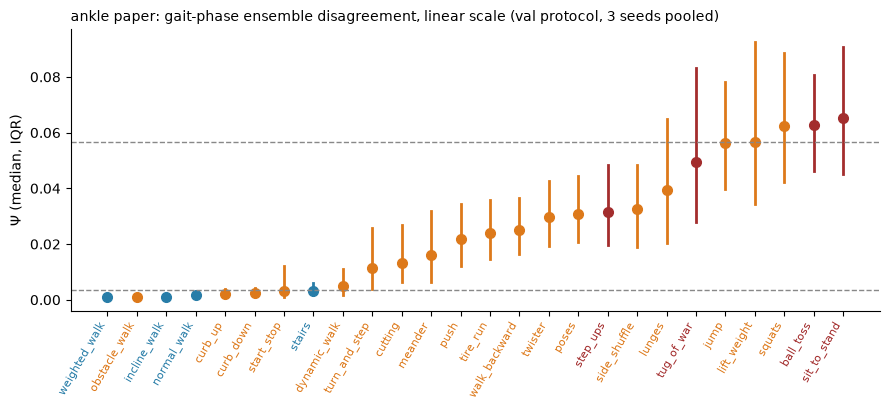

In [7]:
fig, ax = plt.subplots(figsize = (9, 4.2))
eb.plot_per_task(ax, per_psi, cutoffs_psi, r'$\Psi$ (median, IQR)',
                 title = f'ankle paper: gait-phase ensemble disagreement, linear scale ({PROTOCOL} protocol, {len(pooled)} seeds pooled)')
fig.tight_layout()
fig.savefig(FIG_DIR / '10_per_task_linear.png', dpi = 160, bbox_inches = 'tight')
plt.show()

## 4. What $\Psi$ measures

The members disagree where nothing in training pinned them down, and gait phase is undefined off the cycle: the paper
states this limit itself ("gait phase is not well-defined for non-cyclic tasks"). So $\Psi$ should rank tasks by how far
they are from a gait cycle. Here each task's median $\Psi$ against the share of its windows whose insoles show a stride
(`gait_phase.json`), coloured by regime.

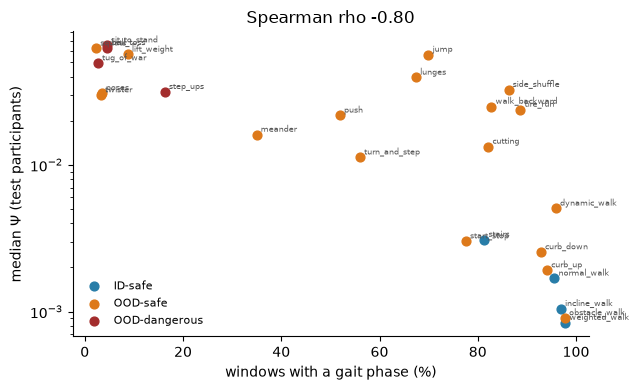

In [8]:
from scipy.stats import spearmanr
per = per_psi.set_index('task').join(coverage[['coverage']])
rho = spearmanr(per['coverage'], per['50%']).statistic
fig, ax = plt.subplots(figsize = (6.5, 4))
for r in rc.REGIMES:
    m = per['regime'] == r
    ax.scatter(100 * per.loc[m, 'coverage'], per.loc[m, '50%'], color = eb.REGIME_C[r], label = r, s = 40)
for task, row in per.iterrows():
    ax.annotate(task, (100 * row['coverage'], row['50%']), fontsize = 6, color = '#555', xytext = (3, 2), textcoords = 'offset points')
ax.set(yscale = 'log', xlabel = 'windows with a gait phase (%)', ylabel = r'median $\Psi$ (test participants)',
       title = f'Spearman rho {rho:.2f}')
ax.legend(frameon = False, fontsize = 8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / '10_psi_vs_phase_coverage.png', dpi = 160, bbox_inches = 'tight')
plt.show()